In [11]:
#setup: imports and output directory for figures and result files.
import time
import numpy as np
import scipy.sparse as sp
import matplotlib.pyplot as plt
from scipy.sparse.linalg import spsolve
from scipy.optimize import brentq
import os
os.makedirs("results", exist_ok=True)

In [12]:
#problem definition----

def build(N, rhs="manufactured"):
  h = 1.0 / (N + 1)
  x = h * np.arange(1, N + 1)
  T = sp.diags([-1.0, 2.0, -1.0], [-1, 0, 1], shape=(N, N)) / h**2
  I = sp.identity(N)
  A = (sp.kron(I, T) + sp.kron(T, I)).tocsr()
  X, Y = np.meshgrid(x, x, indexing="ij")
  u_exact = np.sin(np.pi * X) * np.sin(np.pi * Y)
  b = 2 * np.pi**2 * u_exact if rhs == "manufactured" else np.ones_like(u_exact)

  return A, b.ravel(), u_exact.ravel(), h

In [13]:
#solvers, optional numba JIT compilation (same results even without it but much slower)
try:
  from numba import njit
except ImportError:
  def njit(f):
    return f

In [14]:
"""
solver: Jacobi, SOR (Gauss-seidel = SOR with omega = 1) and unpreconditioned CG, implemented from scratch.
Jacobi and SOR update the padded grid directly, with no matrix assembled
Every solver returns (solution, relative-residual history);
"""

@njit
def _residual_norm(u, B, h2, N):
  s = 0.0
  for i in range(1, N + 1):
    for j in range(1, N + 1):
      r = B[i - 1, j - 1] - (4 * u[i, j] - u[i - 1, j] - u[i + 1, j] - u[i, j - 1] - u[i, j + 1]) / h2
      s += r * r
  return np.sqrt(s)


@njit
def _sor(B, h, omega, tol, maxit):
  N = B.shape[0]
  h2 = h * h
  u = np.zeros((N + 2, N + 2))
  bn = np.sqrt(np.sum(B * B))
  hist = np.zeros(maxit + 1)
  for k in range(maxit + 1):
    hist[k] = _residual_norm(u, B, h2, N) / bn
    if hist[k] < tol:
      return u[1:-1, 1:-1].copy().ravel(), hist[:k + 1]
    for i in range(1, N + 1):
      for j in range(1, N + 1):
        gs = (h2 * B[i - 1, j - 1] + u[i - 1, j] + u[i + 1, j] + u[i, j - 1] + u[i, j + 1]) / 4
        u[i, j] += omega * (gs - u[i, j])

  return u[1:-1, 1:-1].copy().ravel(), hist


@njit
def _jacobi(B, h, tol, maxit):
    N = B.shape[0]
    h2 = h * h
    u = np.zeros((N + 2, N + 2))
    v = np.zeros((N + 2, N + 2))
    bn = np.sqrt(np.sum(B * B))
    hist = np.zeros(maxit + 1)
    for k in range(maxit + 1):
        hist[k] = _residual_norm(u, B, h2, N) / bn
        if hist[k] < tol:
            return u[1:-1, 1:-1].copy().ravel(), hist[:k + 1]
        for i in range(1, N + 1):
            for j in range(1, N + 1):
                v[i, j] = (h2 * B[i - 1, j - 1] + u[i - 1, j] + u[i + 1, j]
                           + u[i, j - 1] + u[i, j + 1]) / 4
        for i in range(1, N + 1):
            for j in range(1, N + 1):
                u[i, j] = v[i, j]
    return u[1:-1, 1:-1].copy().ravel(), hist


def jacobi(b, h, tol=1e-10, maxit=200_000):
  N = int(round(np.sqrt(b.size)))
  return _jacobi(b.reshape(N, N), h, tol, maxit)


def sor(b, h, omega, tol=1e-10, maxit=200_000):
  N = int(round(np.sqrt(b.size)))
  return _sor(b.reshape(N, N), h, omega, tol, maxit)


def optimal_omega(h):
  return 2.0 / (1.0 + np.sin(np.pi * h))

def cg(A, b, tol=1e-10, maxit=20_000):
  x = np.zeros_like(b)
  r = b.copy()
  p = r.copy()
  rs = r @ r
  bn = np.linalg.norm(b)
  hist = [np.sqrt(rs) / bn]
  for _ in range(maxit):
    if hist[-1] < tol:
      break

    Ap = A @ p
    alpha = rs / (p @ Ap)
    x += alpha * p
    r -= alpha * Ap
    rs_new = r @ r
    hist.append(np.sqrt(rs_new) / bn)
    p = r + (rs_new / rs) * p
    rs = rs_new
  return x, np.array(hist)

In [15]:
#All assertions must pass before the experiments below are interpreted.

N = 15

def reference():
  A, b, _, h = build(N, rhs="ones")
  return A, b, h, spsolve(A.tocsc(), b)

def test_matrix_structure():
  A, _, _, _= build(7)
  assert A.shape == (49, 49)
  assert abs(A - A.T).max() == 0
  assert A.getnnz(axis=1).max()== 5

def test_discretisation_error_is_second_order():
  errs, hs = [], []
  for n in (7, 15, 31):
    A, b, u_exact, h = build(n)
    errs.append(np.max(np.abs(spsolve(A.tocsc(), b) - u_exact)))
    hs.append(h)
  slope = np.polyfit(np.log(hs), np.log(errs), 1)[0]
  assert abs(slope - 2) < 0.05

def test_jacobi():
  _, b, h, ref = reference()
  x, _ = jacobi(b, h, tol=1e-10)
  assert np.max(np.abs(x - ref)) < 1e-6

def test_gauss_seidel():
  _, b, h, ref = reference()
  x, _ = sor(b, h, 1.0, tol=1e-10)
  assert np.max(np.abs(x - ref)) < 1e-6

def test_sor():
  _, b, h, ref = reference()
  x, _ = sor(b, h, optimal_omega(h), tol=1e-10)
  assert np.max(np.abs(x - ref)) < 1e-6

def test_cg():
  A, b, h, ref = reference()
  x, _ = cg(A, b, tol=1e-10)
  assert np.max(np.abs(x - ref)) < 1e-6

for t in [test_matrix_structure, test_discretisation_error_is_second_order,
          test_jacobi, test_gauss_seidel, test_sor, test_cg]:
          t()
          print("pass", t.__name__)

pass test_matrix_structure
pass test_discretisation_error_is_second_order
pass test_jacobi
pass test_gauss_seidel
pass test_sor
pass test_cg


N=   7 err=1.295e-02 err/h^2=0.8288
N=  15 err=3.219e-03 err/h^2=0.8241
N=  31 err=8.036e-04 err/h^2=0.8229
N=  63 err=2.008e-04 err/h^2=0.8226
N= 127 err=5.020e-05 err/h^2=0.8225
slope = 2.002


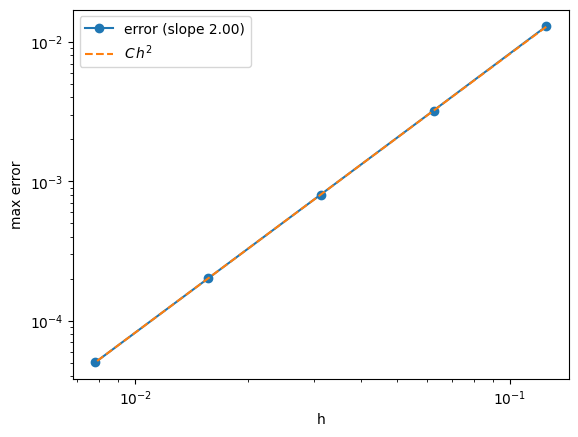

In [16]:
#experiment 1: discretisation convergence


Ns = [7, 15, 31, 63, 127]
hs, errs = [], []
C = np.pi**2 / 12

for N in Ns:
  A, b, u_exact, h = build(N)
  u = spsolve(A.tocsc(), b)
  e = np.max(np.abs(u - u_exact))
  hs.append(h)
  errs.append(e)
  print(f"N={N:4d} err={e:.3e} err/h^2={e / h**2:.4f}")

slope = np.polyfit(np.log(hs), np.log(errs), 1)[0]
print(f"slope = {slope:.3f}")

plt.loglog(hs, errs, "o-", label=f"error (slope {slope:.2f})")
plt.loglog(hs, [C * h**2 for h in hs], "--", label=r"$C\,h^2$")
plt.xlabel("h")
plt.ylabel("max error")
plt.legend()
plt.savefig("results/convergence.png", dpi=150)


N=  7 spsolve        time=   0.338 ms
N=  7 Jacobi iters=   290 time=   0.302 ms |x-ref|=8.7e-12
N=  7 GS     iters=   146 time=   0.137 ms |x-ref|=7.8e-12
N=  7 SOR    iters=    35 time=   0.085 ms |x-ref|=4.6e-12
N=  7 CG     iters=     9 time=   0.160 ms |x-ref|=4.2e-17
N= 15 spsolve        time=   0.706 ms
N= 15 Jacobi iters=  1179 time=   1.316 ms |x-ref|=9.5e-12
N= 15 GS     iters=   591 time=   1.209 ms |x-ref|=9.1e-12
N= 15 SOR    iters=    72 time=   0.225 ms |x-ref|=3.7e-12
N= 15 CG     iters=    30 time=   0.606 ms |x-ref|=8.9e-14
N= 31 spsolve        time=   2.772 ms
N= 31 Jacobi iters=  4734 time=  18.831 ms |x-ref|=9.8e-12
N= 31 GS     iters=  2368 time=  22.725 ms |x-ref|=9.7e-12
N= 31 SOR    iters=   144 time=   1.724 ms |x-ref|=4.2e-12
N= 31 CG     iters=    65 time=   1.707 ms |x-ref|=6.9e-14
N= 63 spsolve        time=  13.086 ms
N= 63 Jacobi iters= 18943 time= 300.322 ms |x-ref|=1.0e-11
N= 63 GS     iters=  9473 time= 405.816 ms |x-ref|=9.9e-12
N= 63 SOR    iters=   

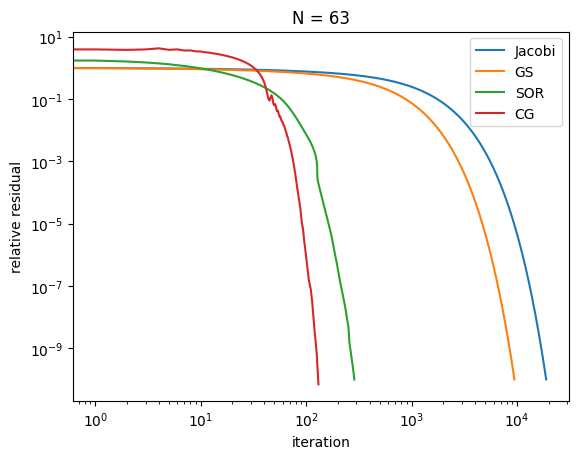

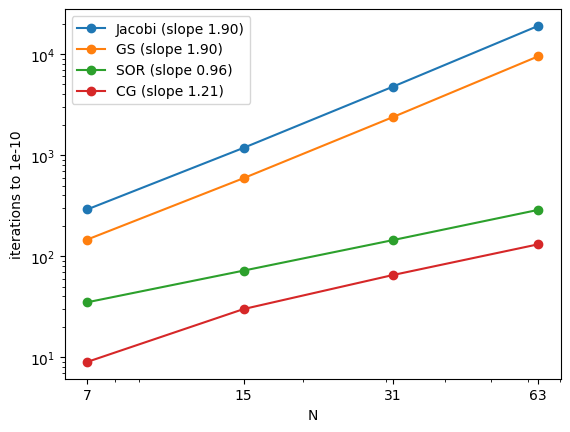

In [17]:
#Experiment 2: iterative-solver comparison (f = 1, tolerance 1e-10).


import json

Ns = [7, 15, 31, 63]
names = ["Jacobi", "GS", "SOR", "CG"]
iters = {m: [] for m in names}
hists = {}
_A, _b, _, _h = build(3, rhs="ones")
jacobi(_b, _h, maxit=5)
sor(_b, _h, 1.0, maxit=5)

def best_time(run, repeats=5):
    times = []
    for _ in range(repeats):
        t = time.perf_counter()
        out = run()
        times.append(time.perf_counter() - t)
    return min(times), out

for N in Ns:
    A, b, u_exact, h = build(N, rhs="ones")
    t_direct, ref = best_time(lambda: spsolve(A.tocsc(), b))
    print(f"N={N:3d} spsolve        time={t_direct*1e3:8.3f} ms")
    omega = optimal_omega(h)
    runs = {
        "Jacobi": lambda: jacobi(b, h),
        "GS": lambda: sor(b, h, 1.0),
        "SOR": lambda: sor(b, h, omega),
        "CG": lambda: cg(A, b),
    }
    for name, run in runs.items():
        dt, (x, hist) = best_time(run)
        n_it = len(hist) - 1

        iters[name].append(n_it)
        hists[(name, N)] = hist
        diff = np.max(np.abs(x - ref))
        print(f"N={N:3d} {name:6s} iters={n_it:6d} time={dt*1e3:8.3f} ms |x-ref|={diff:.1e}")

plt.figure()
for name in names:
    plt.semilogy(hists[(name, Ns[-1])], label=name)
plt.xscale("log")
plt.xlabel("iteration")
plt.ylabel("relative residual")
plt.title(f"N = {Ns[-1]}")
plt.legend()
plt.savefig("results/residuals.png", dpi=150)

plt.figure()
for name in names:
    s = np.polyfit(np.log(Ns), np.log(iters[name]), 1)[0]
    print(f"{name} iteration slope vs N: {s:.2f}")
    plt.loglog(Ns, iters[name], "o-", label=f"{name} (slope {s:.2f})")
plt.xlabel("N")
plt.xticks(Ns, Ns)
plt.ylabel("iterations to 1e-10")
plt.legend()
plt.savefig("results/iterations.png", dpi=150)


with open("results/iterations.json", "w") as fh:
  json.dump({"Ns": Ns, "iters": iters}, fh)

N=15 omega=1.00 iters=591
N=15 omega=1.10 iters=482
N=15 omega=1.20 iters=390
N=15 omega=1.30 iters=312
N=15 omega=1.40 iters=244
N=15 omega=1.50 iters=183
N=15 omega=1.60 iters=126
N=15 omega=1.66 iters=87
N=15 omega=1.68 iters=68
N=15 omega=1.70 iters=74
N=15 omega=1.80 iters=112
N=15 omega=1.82 iters=127
N=15 omega=1.84 iters=143
N=15 omega=1.90 iters=234
N=15 omega=1.92 iters=294
N=15 omega=1.94 iters=396
N=15 omega=1.96 iters=598
N=15 omega=1.98 iters=1207
N=31 omega=1.00 iters=2368
N=31 omega=1.10 iters=1936
N=31 omega=1.20 iters=1575
N=31 omega=1.30 iters=1269
N=31 omega=1.40 iters=1006
N=31 omega=1.50 iters=777
N=31 omega=1.60 iters=574
N=31 omega=1.66 iters=462
N=31 omega=1.68 iters=426
N=31 omega=1.70 iters=390
N=31 omega=1.80 iters=206
N=31 omega=1.82 iters=151
N=31 omega=1.84 iters=150
N=31 omega=1.90 iters=247
N=31 omega=1.92 iters=306
N=31 omega=1.94 iters=404
N=31 omega=1.96 iters=609
N=31 omega=1.98 iters=1225


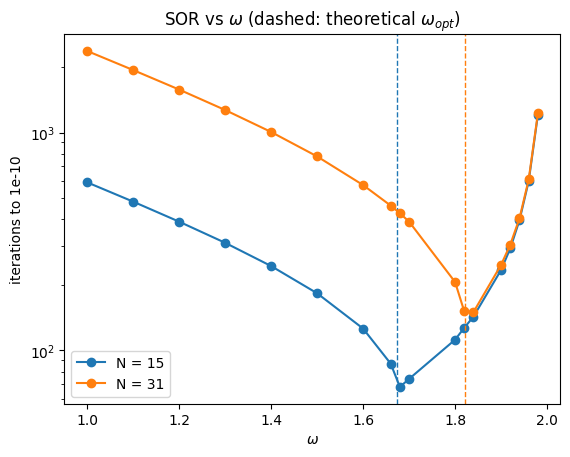

In [18]:
#Experiment 3: SOR sensitivity to the relaxation parameter omega (N = 15, 31)
#dashed lines mark the theoretical w_opt = 2 / (1 + sin pih)

omegas = np.sort(np.concatenate([np.arange(1.0, 1.9, 0.1),
                                 [1.66, 1.68, 1.82, 1.84, 1.90, 1.92, 1.94, 1.96, 1.98]]))
plt.figure()
for N in (15, 31):
  A, b, _, h = build(N, rhs="ones")
  its = []
  for w in omegas:
    _, hist = sor(b, h, w, maxit=20_000)
    its.append(len(hist) - 1)
    print(f"N={N} omega={w:.2f} iters={its[-1]}")
  line, = plt.semilogy(omegas, its, "o-", label=f"N = {N}")
  plt.axvline(optimal_omega(h), color=line.get_color(), ls="--", lw=1)

plt.xlabel(r"$\omega$")
plt.ylabel("iterations to 1e-10")
plt.title(r"SOR vs $\omega$ (dashed: theoretical $\omega_{opt}$)")
plt.legend()
plt.savefig("results/sor_omega.png", dpi=150)

In [19]:
#analysis: measured iteration counts against theoretical predictions
#


import json

tol = 1e-10
with open("results/iterations.json") as fh:
  d = json.load(fh)

L = np.log(tol)
rows = ["| N | method | measured | predicted | measured/predicted |",
"|---|--------|----------|------------|---------------------|"]

for k, N in enumerate(d["Ns"]):
  h = 1 / (N + 1)
  rho_j = np.cos(np.pi * h)
  w = 2 / (1 + np.sin(np.pi * h))
  pred = {
      "Jacobi": L / np.log(rho_j),
      "GS": L / np.log(rho_j**2),
      "SOR": L / np.log(w - 1),
      "SOR (k rho^k)": brentq(lambda k: np.log(k) + k * np.log(w - 1) - L, 1, 1e6),
      "CG (bound)": 0.5 / np.tan(np.pi * h / 2) * np.log(2 / tol),
  }
  meas = {"Jacobi": d["iters"]["Jacobi"][k], "GS": d["iters"]["GS"][k], "SOR": d["iters"]["SOR"][k], "CG (bound)": d["iters"]["CG"][k], "SOR (k rho^k)": d["iters"]["SOR"][k]}

  for m in pred:
    rows.append(f"| {N} | {m} | {meas[m]} | {pred[m]:.0f} | {meas[m] / pred[m]:.2f} |")
out = "\n".join(rows)
print(out)
open("results/theory_table.md", "w").write(out + "\n")

| N | method | measured | predicted | measured/predicted |
|---|--------|----------|------------|---------------------|
| 7 | Jacobi | 290 | 291 | 1.00 |
| 7 | GS | 146 | 145 | 1.00 |
| 7 | SOR | 35 | 29 | 1.23 |
| 7 | SOR (k rho^k) | 35 | 33 | 1.06 |
| 7 | CG (bound) | 9 | 60 | 0.15 |
| 15 | Jacobi | 1179 | 1187 | 0.99 |
| 15 | GS | 591 | 593 | 1.00 |
| 15 | SOR | 72 | 58 | 1.24 |
| 15 | SOR (k rho^k) | 72 | 69 | 1.04 |
| 15 | CG (bound) | 30 | 120 | 0.25 |
| 31 | Jacobi | 4734 | 4770 | 0.99 |
| 31 | GS | 2368 | 2385 | 0.99 |
| 31 | SOR | 144 | 117 | 1.23 |
| 31 | SOR (k rho^k) | 144 | 142 | 1.01 |
| 31 | CG (bound) | 65 | 241 | 0.27 |
| 63 | Jacobi | 18943 | 19104 | 0.99 |
| 63 | GS | 9473 | 9552 | 0.99 |
| 63 | SOR | 287 | 234 | 1.22 |
| 63 | SOR (k rho^k) | 287 | 292 | 0.98 |
| 63 | CG (bound) | 131 | 483 | 0.27 |


830